<a href="https://colab.research.google.com/github/madewitt55/cs407-final-project/blob/Prithvi-tasks/CS407_PlaylistPro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PlaylistPro — Predicting Customer Churn
**CS407 | Group Project 4 | Tasks 1–5**

**My question:** Can I use customers’ listening, subscription and support activity to predict whether they might cancel PlaylistPro?

I use **`churned = 1`** when a customer canceled and **`churned = 0`** when they stayed. I’ll explain the steps in simple words, show what each graph tells me, and finish with practical ideas to reduce churn.

**How to run this in Google Colab:**
1. Upload **`train.csv`** and **`test.csv`** using the Files icon on the left.
2. Click **Runtime → Run all**. The notebook will find the CSV files automatically; if it cannot find them, it will let me upload them.
3. Read the explanations next to each result. They are based on the numbers calculated from my files.

The project follows our class topics on data cleaning, feature engineering, logistic regression, k-nearest neighbors, decision trees, cross-validation, and classification metrics.

## Task 1 — Data cleaning and understanding the customers
**My goal:** Check that the dataset makes sense, clean clear problems, and explore how churn relates to customer behavior. This gives me a starting point before I build a model.

### 1.1 Load the data and libraries
I start by loading my two CSV files. The training file includes the real `churned` answer; the other file has customer details but no churn answers. I use **`train`** and **`test`** consistently so later cells do not fail because of different names.

In [2]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve)

SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', 45)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def find_csv(filename, required=True):
    """Find uploaded Colab CSVs (also supports local Jupyter)."""
    folders = [Path('/content'), Path.cwd(), Path('/mnt/data')]
    for folder in folders:
        path = folder / filename
        if path.is_file():
            return path
    if not required:
        return None
    # Only ask for an upload when really necessary in Colab.
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f'Missing {filename}. Put it beside this notebook.')
    print(f'I could not find {filename}. Please upload {filename} now.')
    files.upload()
    for folder in folders:
        path = folder / filename
        if path.is_file():
            return path
    raise FileNotFoundError(f'I still cannot find {filename}. Check the filename in the left Files panel.')

train = pd.read_csv(find_csv('train.csv'))
test = pd.read_csv(find_csv('test.csv'))

assert 'churned' in train.columns, 'Training file needs a churned column.'
assert 'churned' not in test.columns, 'The unlabeled test file should not have churned answers.'
assert 'customer_id' in train and 'customer_id' in test, 'Both files need customer_id.'
assert train.churned.notna().all() and set(train.churned.unique()).issubset({0,1}), 'Churn labels should be 0/1 with no missing values.'
print(f'Training data: {len(train):,} rows, {train.shape[1]} columns')
print(f'Test data: {len(test):,} rows, {test.shape[1]} columns')
print('My training file preview:')
display(train.head(3))

Training data: 125,000 rows, 20 columns
Test data: 75,000 rows, 19 columns
My training file preview:


,customer_id,age,location,subscription_type,payment_plan,num_subscription_pauses,payment_method,customer_service_inquiries,signup_date,weekly_hours,average_session_length,song_skip_rate,weekly_songs_played,weekly_unique_songs,num_favorite_artists,num_platform_friends,num_playlists_created,num_shared_playlists,notifications_clicked,churned
0,1,32,Montana,Free,Yearly,2,Paypal,Medium,-1606,22.391362,105.394516,0.176873,169,109,18,32,52,35,46,0
1,2,64,New Jersey,Free,Monthly,3,Paypal,Low,-2897,29.294210,52.501115,0.981811,55,163,44,33,12,25,37,1
2,3,51,Washington,Premium,Yearly,2,Credit Card,High,-348,15.400312,24.703696,0.048411,244,117,20,129,50,28,38,0


### 1.2 Check for missing values and duplicates
I check how many rows and columns I have, whether any information is missing, and whether a customer appears more than once.

**Why I check:** Missing or repeated records could lead the model to learn the wrong patterns. I do not automatically delete customers just because one value looks unusual.

In [3]:
checks = pd.DataFrame({
    'Train': [len(train), train.isna().sum().sum(), train.duplicated().sum(), train.customer_id.duplicated().sum()],
    'Test': [len(test), test.isna().sum().sum(), test.duplicated().sum(), test.customer_id.duplicated().sum()]},
    index=['Rows', 'Missing cells', 'Duplicate full rows', 'Duplicate IDs'])
display(checks)
display(pd.DataFrame({'type': train.dtypes.astype(str), 'missing': train.isna().sum()}))
assert train['churned'].notna().all(), 'Some training labels are missing. I need to review these before modeling.'
assert train.customer_id.is_unique and test.customer_id.is_unique, 'Please review duplicate customer IDs before running models.'
print('My takeaway: I checked data quality first. Any missing predictor values will be filled during model training, not by looking at the holdout group.')

,Train,Test
Rows,125000,75000
Missing cells,0,0
Duplicate full rows,0,0
Duplicate IDs,0,0


,type,missing
customer_id,int64,0
age,int64,0
location,object,0
subscription_type,object,0
payment_plan,object,0
num_subscription_pauses,int64,0
payment_method,object,0
customer_service_inquiries,object,0
signup_date,int64,0
weekly_hours,float64,0


My takeaway: I checked data quality first. Any missing predictor values will be filled during model training, not by looking at the holdout group.


### 1.3 Clean the mistakes I can identify
I fix the spelling of `Nebrasksa` to `Nebraska` and check for values that should not happen, such as negative listening hours or more unique songs than total songs played.

If I cannot know the correct number, I leave it missing and let the training pipeline handle it later. I also keep a flag showing where song counts were inconsistent.

In [4]:
def clean_data(raw):
    df = raw.copy()
    if 'location' in df:
        df['location'] = df['location'].map(lambda x: x.strip() if isinstance(x, str) else x)
        df['location'] = df['location'].replace({'Nebrasksa': 'Nebraska'})
    numeric_fields = ['weekly_hours', 'weekly_songs_played', 'weekly_unique_songs',
                      'song_skip_rate', 'average_session_length', 'num_subscription_pauses',
                      'num_playlists_created', 'num_shared_playlists', 'num_platform_friends',
                      'notifications_clicked']
    for col in numeric_fields:
        if col in df:
            df[col] = pd.to_numeric(df[col], errors='coerce')
    bad = {}
    if 'weekly_hours' in df:
        mask = (df.weekly_hours < 0) | (df.weekly_hours > 168)
        bad['Impossible weekly hours'] = int(mask.sum())
        df.loc[mask, 'weekly_hours'] = np.nan
    if 'song_skip_rate' in df:
        mask = (df.song_skip_rate < 0) | (df.song_skip_rate > 1)
        bad['Skip rate outside 0–1'] = int(mask.sum())
        df.loc[mask, 'song_skip_rate'] = np.nan
    if 'average_session_length' in df:
        mask = df.average_session_length <= 0
        bad['Nonpositive session length'] = int(mask.sum())
        df.loc[mask, 'average_session_length'] = np.nan
    for col in [x for x in numeric_fields if x.startswith('num_') or x in ['weekly_songs_played','weekly_unique_songs','notifications_clicked']]:
        if col in df:
            mask = df[col] < 0
            bad['Negative '+col] = int(mask.sum())
            df.loc[mask, col] = np.nan
    if {'weekly_unique_songs', 'weekly_songs_played'}.issubset(df):
        invalid = df.weekly_unique_songs > df.weekly_songs_played
        df['song_count_issue'] = invalid.fillna(False).astype(int)
        bad['Unique songs exceed total songs'] = int(invalid.sum())
        # Do not trust an impossible unique-song count when calculating the ratio.
        df.loc[invalid, 'weekly_unique_songs'] = np.nan
    return df, bad

train_clean, train_issues = clean_data(train)
test_clean, test_issues = clean_data(test)
print('Problem counts (train):'); display(pd.Series(train_issues, name='Count'))
print('Problem counts (test):'); display(pd.Series(test_issues, name='Count'))
print(f"Nebraska typo left in training data: {(train_clean.get('location', pd.Series(dtype='object')) == 'Nebrasksa').sum()}")
print('My take: I cleaned the obvious mistakes, but I kept the original rows. Missing-value filling happens during training.')

Problem counts (train):


,Count
Impossible weekly hours,0
Skip rate outside 0–1,0
Nonpositive session length,0
Negative weekly_songs_played,0
Negative weekly_unique_songs,0
Negative num_subscription_pauses,0
Negative num_playlists_created,0
Negative num_shared_playlists,0
Negative num_platform_friends,0
Negative notifications_clicked,0


Problem counts (test):


,Count
Impossible weekly hours,0
Skip rate outside 0–1,0
Nonpositive session length,0
Negative weekly_songs_played,0
Negative weekly_unique_songs,0
Negative num_subscription_pauses,0
Negative num_playlists_created,0
Negative num_shared_playlists,0
Negative num_platform_friends,0
Negative notifications_clicked,0


Nebraska typo left in training data: 0
My take: I cleaned the obvious mistakes, but I kept the original rows. Missing-value filling happens during training.


### 1.4 Handle the signup date carefully
A normal signup date could tell me roughly how long a customer has been using PlaylistPro. In these files, the field is stored as a **negative number**, not a normal calendar date.

I keep its size as a *possible tenure signal*, but I will not pretend I know the exact unit. This is one limit of the dataset.

In [5]:
OBSERVATION_DATE = None   # Example only if known from assignment: 'YYYY-MM-DD'

def date_features(df):
    df = df.copy()
    if 'signup_date' not in df: return df, 'No signup_date column.'
    original = df['signup_date']
    numeric = pd.to_numeric(original, errors='coerce')
    if pd.api.types.is_numeric_dtype(original) or numeric.notna().mean() >= 0.95:
        if len(numeric.dropna()) and (numeric.dropna() <= 0).mean() >= .99:
            df['tenure_proxy'] = -numeric
            message = 'Negative signup codes: I used their magnitude as an unverified tenure proxy, not confirmed calendar days.'
        else:
            df['signup_numeric_code'] = numeric
            message = 'Numeric signup codes: I kept their values without claiming a time unit.'
        df = df.drop(columns='signup_date')
        return df, message
    parsed = pd.to_datetime(original, errors='coerce')
    if parsed.notna().mean() >= 0.90:
        df['signup_year'] = parsed.dt.year
        df['signup_month'] = parsed.dt.month
        df['signup_day_of_week'] = parsed.dt.dayofweek
        if OBSERVATION_DATE is not None:
            reference = pd.Timestamp(OBSERVATION_DATE)
            df['tenure_days'] = (reference - parsed).dt.days.clip(lower=0)
        df = df.drop(columns='signup_date')
        return df, 'I parsed signup dates; tenure_days appears only when I know the observation date.'
    df = df.drop(columns='signup_date')
    return df, 'The signup_date format was unclear, so I excluded it rather than guessing.'

train_clean, train_date_message = date_features(train_clean)
test_clean, test_date_message = date_features(test_clean)
print(train_date_message)
assert list(train_clean.drop(columns='churned').columns) == list(test_clean.columns), 'Date/cleaning columns differ between train and test.'
print('I will be careful not to call a numeric signup code an exact tenure measurement.')

Negative signup codes: I used their magnitude as an unverified tenure proxy, not confirmed calendar days.
I will be careful not to call a numeric signup code an exact tenure measurement.


### 1.5 Figure 1 — How many customers stayed or canceled?
This bar chart counts customers in each group. I also print the percentages so I can see whether cancellation is rare or fairly common.

**Why it matters:** If almost everyone belonged to one group, a model could appear accurate just by guessing that group.

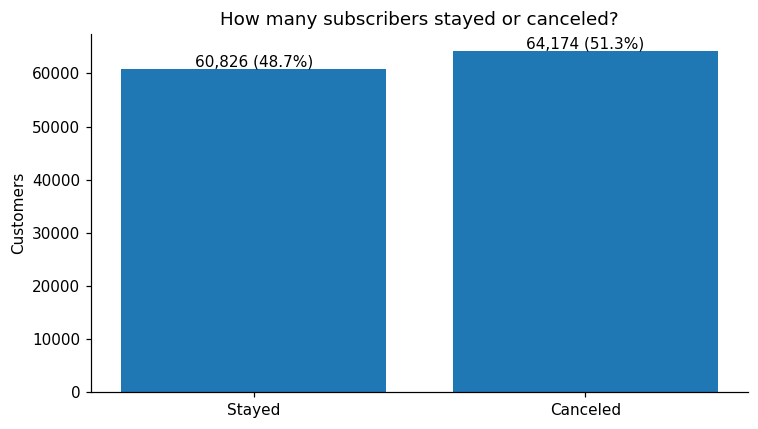

What I see: 51.3% canceled and 48.7% stayed.
A model that always guesses the majority class would score 51.3% accuracy. I need to compare against that baseline. I also check precision, recall, F1 and PR-AUC.


In [6]:
counts = train_clean['churned'].value_counts().reindex([0,1], fill_value=0)
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(['Stayed', 'Canceled'], counts.values)
ax.set(title='How many subscribers stayed or canceled?', ylabel='Customers')
for i, value in enumerate(counts): ax.text(i, value, f'{value:,} ({value/len(train_clean):.1%})', ha='center', va='bottom')
plt.tight_layout(); plt.show()
print(f"What I see: {counts[1]/len(train_clean):.1%} canceled and {counts[0]/len(train_clean):.1%} stayed.")
print(f"A model that always guesses the majority class would score {counts.max()/len(train_clean):.1%} accuracy. I need to compare against that baseline. I also check precision, recall, F1 and PR-AUC.")

### 1.6 Figure 2 — Does churn change by subscription plan?
Each bar shows the **percentage who canceled within that plan**. I use percentages rather than totals because some plans may have more customers than others.

**How I read it:** A taller bar means a higher observed cancellation rate in that plan, not proof that the plan itself made customers cancel.

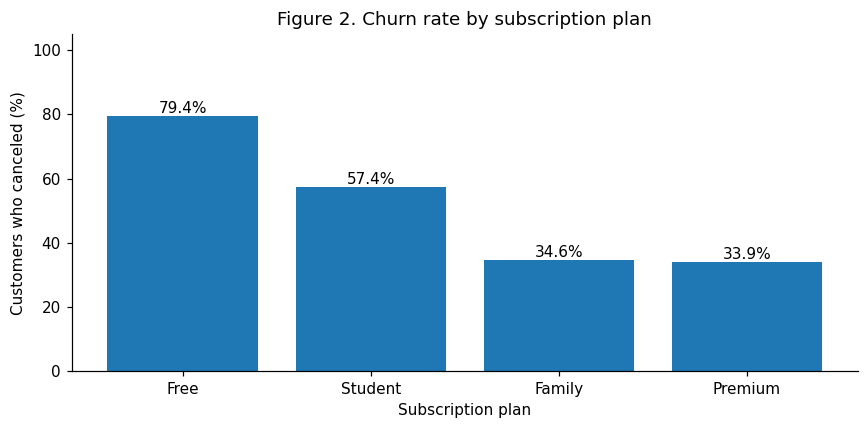

,churn_rate,customers
subscription_type,,
Free,0.794,31269
Student,0.574,31305
Family,0.346,31072
Premium,0.339,31354


What I see: Free had the highest churn (79.4%) and Premium the lowest (33.9%).
That is a relationship in this dataset, not proof the plan caused cancellation.


In [7]:
if 'subscription_type' in train_clean:
    by_plan = train_clean.groupby('subscription_type')['churned'].agg(['mean','size']).sort_values('mean', ascending=False)
    fig, ax = plt.subplots(figsize=(8,4))
    ax.bar(by_plan.index.astype(str), by_plan['mean']*100)
    ax.set(title='Figure 2. Churn rate by subscription plan', ylabel='Customers who canceled (%)', xlabel='Subscription plan', ylim=(0,105))
    for i,v in enumerate(by_plan['mean']): ax.text(i,100*v+1,f'{v:.1%}',ha='center')
    plt.tight_layout(); plt.show()
    display(by_plan.rename(columns={'mean':'churn_rate','size':'customers'}).round(3))
    print(f"What I see: {by_plan.index[0]} had the highest churn ({by_plan.iloc[0]['mean']:.1%}) and {by_plan.index[-1]} the lowest ({by_plan.iloc[-1]['mean']:.1%}).")
    print('That is a relationship in this dataset, not proof the plan caused cancellation.')

### 1.7 Figure 3 — Customer support and churn
I compare cancellation rates for customers with different levels of support inquiries.

**How I read it:** If churn is higher in one support group, it could help me decide where to look for service problems. This graph does not prove that support inquiries caused churn.

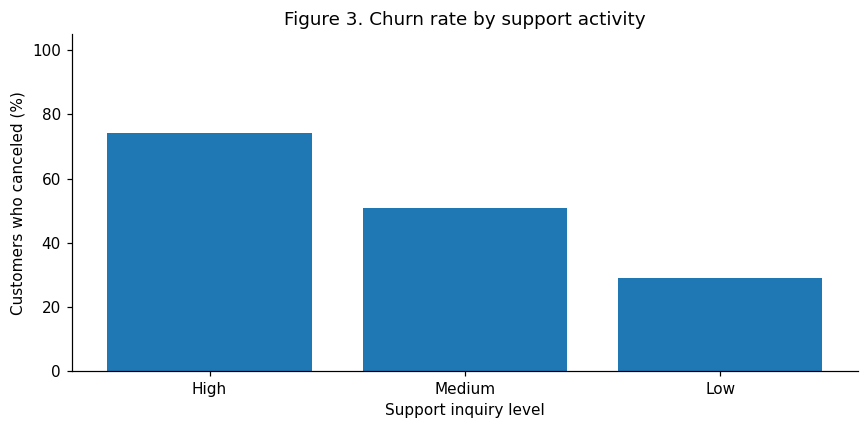

,churn_rate,customers
customer_service_inquiries,,
High,0.743,41583
Medium,0.509,41544
Low,0.289,41873


What I see: The highest observed rate was in High (74.3%).
I would test whether faster support helps before claiming it prevents cancellations.


In [8]:
if 'customer_service_inquiries' in train_clean:
    by_support = train_clean.groupby('customer_service_inquiries')['churned'].agg(['mean','size']).sort_values('mean',ascending=False)
    fig, ax = plt.subplots(figsize=(8,4))
    ax.bar(by_support.index.astype(str), by_support['mean']*100)
    ax.set(title='Figure 3. Churn rate by support activity', ylabel='Customers who canceled (%)', xlabel='Support inquiry level', ylim=(0,105))
    plt.tight_layout(); plt.show()
    display(by_support.rename(columns={'mean':'churn_rate','size':'customers'}).round(3))
    print(f"What I see: The highest observed rate was in {by_support.index[0]} ({by_support.iloc[0]['mean']:.1%}).")
    print('I would test whether faster support helps before claiming it prevents cancellations.')

### 1.8 Figure 4 — Listening, skipping, and subscription pauses
I use **boxplots** to compare three behaviors between the customers who stayed and the customers who canceled.

**How I read a boxplot:** The line inside each box is the typical middle value (median). A higher box means the values generally sit higher, and the box height shows how spread out the middle half of customers is. The units are different for each small graph, so I compare *within* a graph, not between graphs.

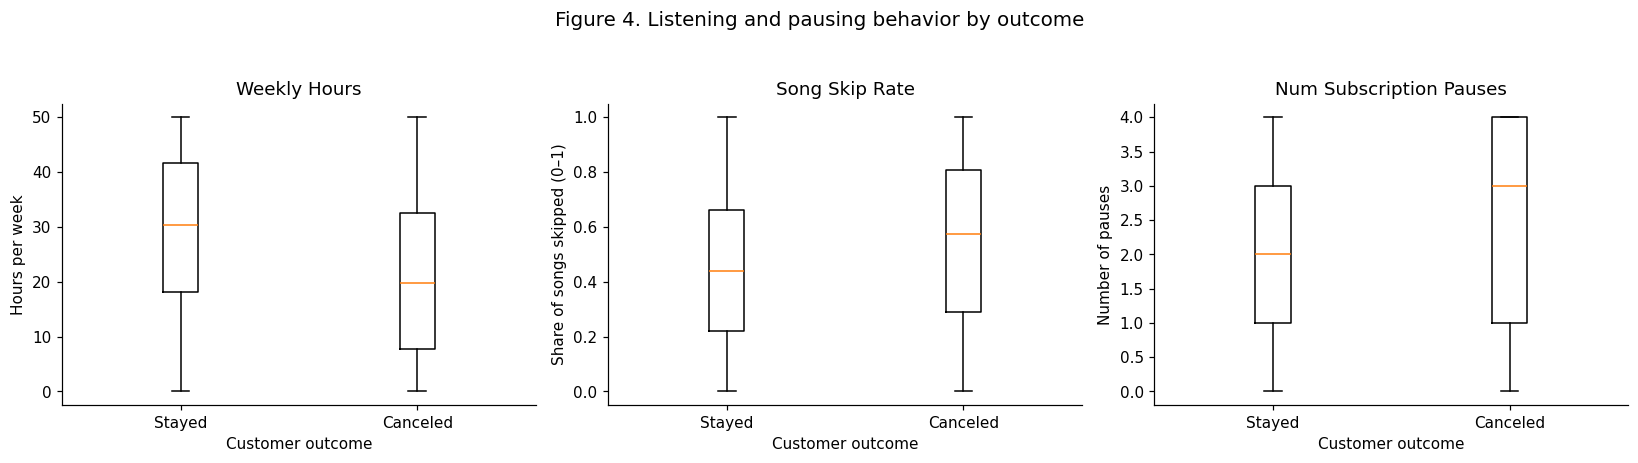

What I see for weekly_hours: the typical value was 30.45 among people who stayed and 19.71 among people who canceled.
What I see for song_skip_rate: the typical value was 0.44 among people who stayed and 0.57 among people who canceled.
What I see for num_subscription_pauses: the typical value was 2.00 among people who stayed and 3.00 among people who canceled.


In [9]:
behavior_cols = [c for c in ['weekly_hours','song_skip_rate','num_subscription_pauses'] if c in train_clean]
fig, axes = plt.subplots(1, len(behavior_cols), figsize=(5*len(behavior_cols),4))
axes = np.atleast_1d(axes)
for ax, col in zip(axes, behavior_cols):
    pair = [train_clean.loc[train_clean.churned==v, col].dropna() for v in [0,1]]
    ax.boxplot(pair, tick_labels=['Stayed','Canceled'], showfliers=False)
    ax.set(title=col.replace('_',' ').replace('Weekly Hours','Weekly Listening Hours').title(), xlabel='Customer outcome', ylabel={'weekly_hours':'Hours per week','song_skip_rate':'Share of songs skipped (0–1)','num_subscription_pauses':'Number of pauses'}[col])
fig.suptitle("Figure 4. Listening and pausing behavior by outcome", fontsize=13, y=1.04)
plt.tight_layout(); plt.show()
for col in behavior_cols:
    a = train_clean.groupby('churned')[col].median()
    print(f"What I see for {col}: the typical value was {a.get(0,np.nan):.2f} among people who stayed and {a.get(1,np.nan):.2f} among people who canceled.")

## Task 2 — Feature engineering
**My goal:** Create a few new variables that summarize customer behavior more clearly. A *feature* is simply a piece of information the model uses to make a prediction.

### 2.1 Create new features from customer activity
I build features around listening habits, playlists, social activity, subscription pauses, notifications and support interactions.

| New feature | What I am measuring |
|---|---|
| Estimated weekly sessions | Approximate listening sessions per week, assuming the average session is measured in minutes |
| Unique-song ratio | How much variety there is in what someone listens to |
| Songs kept playing | Total songs adjusted for the skip rate |
| Songs per hour | Rough listening pace |
| Playlist activity | Playlists created plus playlists shared |
| Social engagement | Platform friends plus shared playlists |
| Shares per friend | Shares relative to number of friends |
| Has paused | Whether the customer has paused a subscription |
| High skip + low listening | Whether both signs of lower engagement occur together |
| Notifications per hour | Notification clicks compared with listening time |
| High support activity | Whether support activity is marked high |
| Free plan + low listening | Whether a Free-plan customer listens less than 10 hours weekly |

I keep the original columns, too. New features are useful only if testing shows they actually help.

In [10]:
def make_features(df):
    d = df.copy()
    required = ['weekly_hours','average_session_length','weekly_songs_played',
                'weekly_unique_songs','song_skip_rate','num_subscription_pauses',
                'num_playlists_created','num_shared_playlists','num_platform_friends',
                'notifications_clicked']
    missing = [c for c in required if c not in d]
    if missing: raise ValueError(f'I need these columns for feature engineering: {missing}')
    hours = d.weekly_hours.where(d.weekly_hours > 0)
    session = d.average_session_length.where(d.average_session_length > 0)
    d['estimated_weekly_sessions'] = (d.weekly_hours*60/session).replace([np.inf,-np.inf],np.nan)
    valid = (d.weekly_songs_played > 0) & (d.weekly_unique_songs <= d.weekly_songs_played)
    d['unique_song_ratio'] = (d.weekly_unique_songs / d.weekly_songs_played.where(valid)).replace([np.inf,-np.inf],np.nan)
    d['songs_kept_playing'] = d.weekly_songs_played * (1 - d.song_skip_rate)
    d['songs_per_hour'] = (d.weekly_songs_played / hours).replace([np.inf,-np.inf],np.nan)
    d['playlist_activity'] = d.num_playlists_created + d.num_shared_playlists
    d['social_engagement'] = d.num_platform_friends + d.num_shared_playlists
    d['shares_per_friend'] = d.num_shared_playlists / (d.num_platform_friends + 1)
    d['has_paused'] = (d.num_subscription_pauses > 0).astype(int)
    d['high_skip_low_listening'] = ((d.song_skip_rate > .50) & (d.weekly_hours < 10)).astype(int)
    d['notifications_per_hour'] = d.notifications_clicked / (d.weekly_hours + 1)
    if 'customer_service_inquiries' in d:
        d['support_high'] = (d.customer_service_inquiries.astype(str).str.lower() == 'high').astype(int)
    if 'subscription_type' in d:
        d['free_plan_and_low_listening'] = ((d.subscription_type.astype(str).str.lower() == 'free') & (d.weekly_hours < 10)).astype(int)
    return d.replace([np.inf,-np.inf],np.nan)

train_fe = make_features(train_clean)
test_fe = make_features(test_clean)
new_features = sorted(set(train_fe.columns) - set(train_clean.columns))
print('Features I made:', ', '.join(new_features))
display(train_fe[new_features + ['churned']].head(3))
assert list(train_fe.drop(columns='churned').columns) == list(test_fe.columns), 'Train/test feature columns should match.'

Features I made: estimated_weekly_sessions, free_plan_and_low_listening, has_paused, high_skip_low_listening, notifications_per_hour, playlist_activity, shares_per_friend, social_engagement, songs_kept_playing, songs_per_hour, support_high, unique_song_ratio


,estimated_weekly_sessions,free_plan_and_low_listening,has_paused,high_skip_low_listening,notifications_per_hour,playlist_activity,shares_per_friend,social_engagement,songs_kept_playing,songs_per_hour,support_high,unique_song_ratio,churned
0,12.747169,0,1,0,1.966538,87.0,1.060606,67.0,139.108484,7.547554,0,0.644970,0
1,33.478386,0,1,0,1.221355,37.0,0.735294,58.0,1.000403,1.877504,0,NaN,1
2,37.404068,0,1,0,2.317029,78.0,0.215385,157.0,232.187706,15.843835,1,0.479508,0


### 2.2 Figure 5 — My combined listening signal
I compare two groups: customers who **skip more than half their songs and listen fewer than 10 hours a week**, versus everyone else.

The bar heights show what percentage canceled in each group. I want to see whether combining these two behaviors reveals something useful.

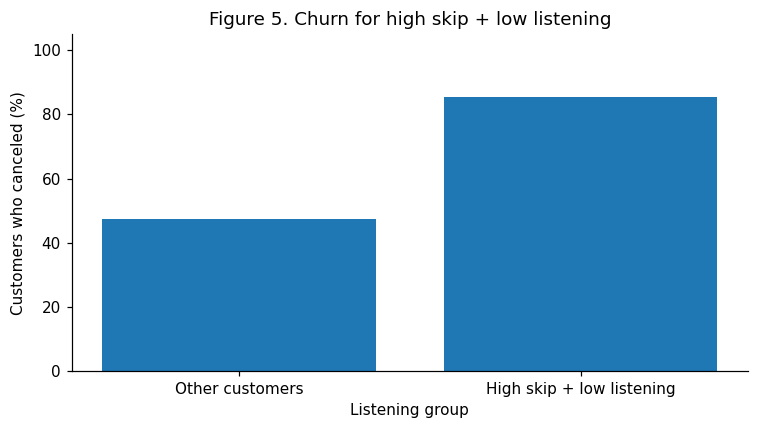

,churn_rate,customers
high_skip_low_listening,,
0,0.475698,112523
1,0.853330,12477


What I see: 85.3% of the high-skip/low-listening group canceled, compared with 47.6% of the others.
This is a pattern, not proof that skipping songs makes people cancel.


In [11]:
risk = train_fe.groupby('high_skip_low_listening')['churned'].agg(['mean','size']).reindex([0,1])
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(['Other customers','High skip + low listening'], 100*risk['mean'].fillna(0))
ax.set(title='Figure 5. Churn for high skip + low listening', ylabel='Customers who canceled (%)', xlabel='Listening group', ylim=(0,105))
plt.tight_layout(); plt.show()
display(risk.rename(columns={'mean':'churn_rate','size':'customers'}))
if risk['size'].notna().all():
    print(f"What I see: {risk.loc[1,'mean']:.1%} of the high-skip/low-listening group canceled, compared with {risk.loc[0,'mean']:.1%} of the others.")
else:
    print('One group was empty, so I cannot make a meaningful comparison here.')
print('This is a pattern, not proof that skipping songs makes people cancel.')

### 2.3 Figure 6 — Compare my engineered features
These small charts compare average feature values for the customers who stayed and those who canceled.

**How I read it:** Within each chart, I check which group has the higher average. The features use different units, so I should **not** compare the bar heights from one chart to another.

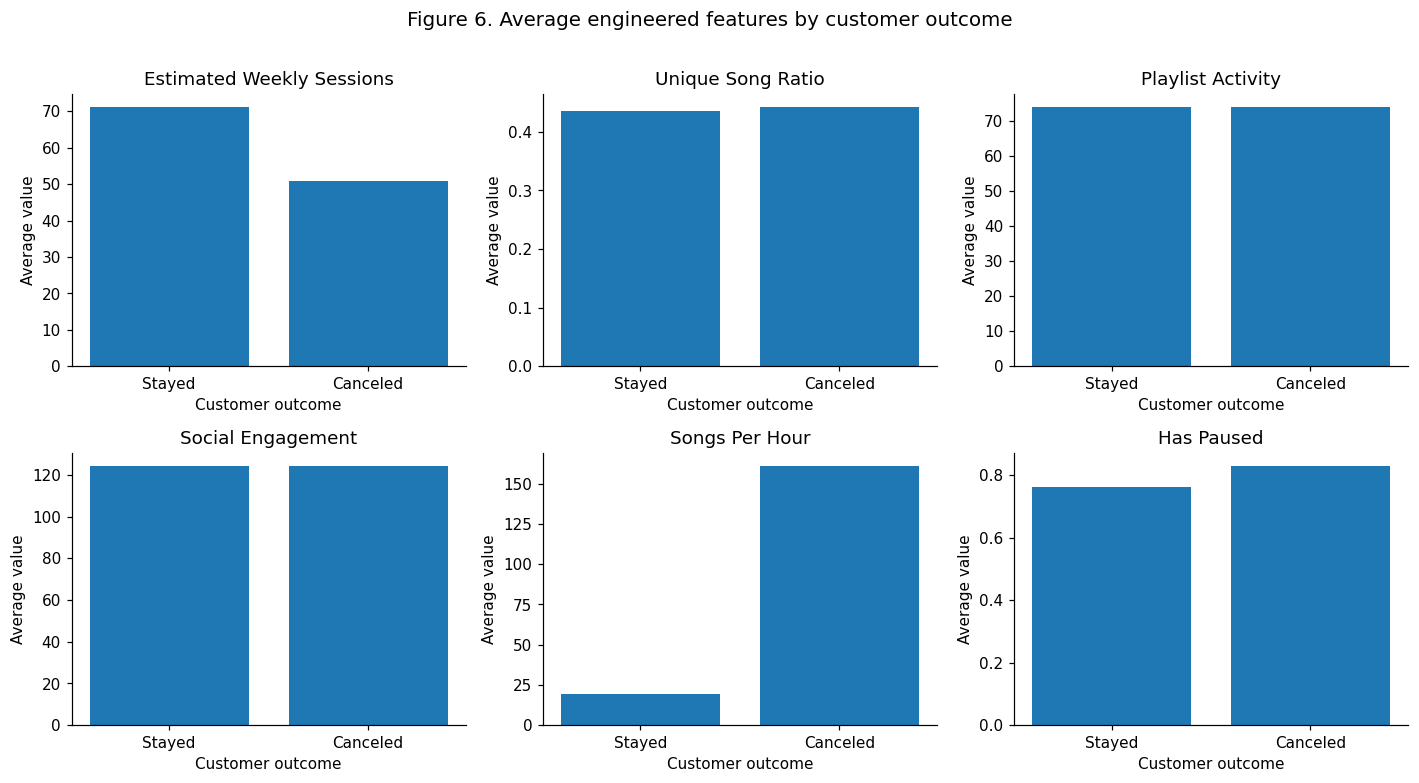

churned,Stayed,Canceled
estimated_weekly_sessions,71.264,50.765
unique_song_ratio,0.436,0.443
playlist_activity,74.021,74.004
social_engagement,124.389,124.153
songs_per_hour,19.452,161.249
has_paused,0.762,0.830


My take: I can see where the averages differ, but I need validation to know whether these features actually help.


In [12]:
cols_show = [c for c in ['estimated_weekly_sessions','unique_song_ratio','playlist_activity',
                             'social_engagement','songs_per_hour','has_paused'] if c in train_fe]
means = train_fe.groupby('churned')[cols_show].mean().T
fig, axs = plt.subplots(2,3,figsize=(13,7))
for ax,col in zip(axs.flat,cols_show):
    ax.bar(['Stayed','Canceled'],means.loc[col].reindex([0,1]))
    ax.set(title=col.replace('_',' ').title(), xlabel='Customer outcome', ylabel='Average value')
for ax in axs.flat[len(cols_show):]: ax.axis('off')
fig.suptitle("Figure 6. Average engineered features by customer outcome", fontsize=13, y=1.01)
plt.tight_layout(); plt.show()
display(means.rename(columns={0:'Stayed',1:'Canceled'}).round(3))
print('My take: I can see where the averages differ, but I need validation to know whether these features actually help.')

In [13]:

# Group individual states into larger US regions

region_states = {
    "Northeast": [
        "Maine", "Vermont", "New York", "New Jersey"
    ],
    "Midwest": [
        "Nebraska", "North Dakota", "Wisconsin"
    ],
    "South": [
        "Alabama", "Florida", "Georgia",
        "North Carolina", "South Carolina",
        "Virginia", "West Virginia"
    ],
    "West": [
        "California", "Idaho", "Montana",
        "Utah", "Washington"
    ]
}

state_to_region = {
    state: region
    for region, states in region_states.items()
    for state in states
}

# Works with both datasets
for df in [train, test]:
    df["region"] = (
        df["location"]
        .replace({"Nebrasksa": "Nebraska"})
        .map(state_to_region)
        .fillna("Unknown")
    )

print(train[["location", "region"]].head())

# Compare churn rates by region
region_churn = (
    train.groupby("region")["churned"]
    .agg(["mean", "size"])
)

region_churn["churn_pct"] = (
    region_churn["mean"] * 100
)

display(region_churn)


     location     region
0     Montana       West
1  New Jersey  Northeast
2  Washington       West
3  California       West
4  Washington       West


,mean,size,churn_pct
region,,,
Midwest,0.515382,19731,51.538189
Northeast,0.512137,26407,51.213693
South,0.512859,45884,51.285851
West,0.513949,32978,51.394869


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


,Customers,Churn Rate
songs_per_hour_group,,
<10,62480,42.52
10-20,31182,49.94
20-30,10421,55.97
30-40,5259,61.84
40-60,5232,74.06
60+,10426,87.03


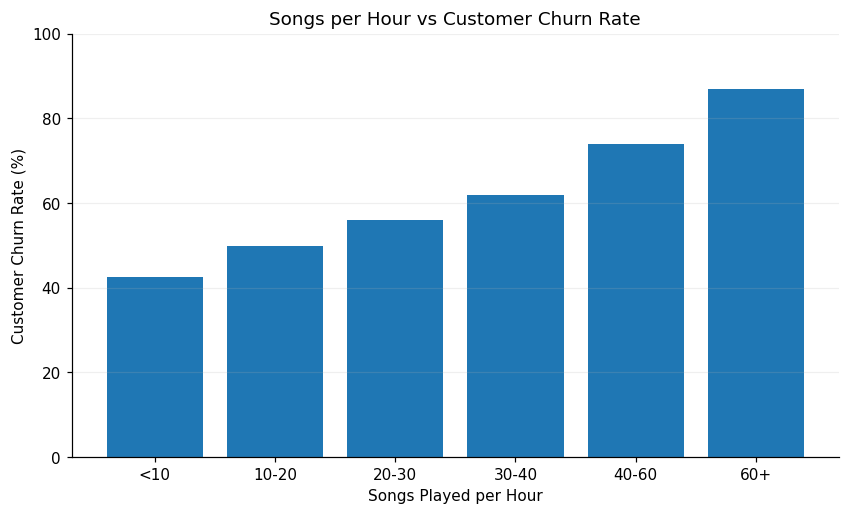

In [29]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Create Songs per Hour
train["songs_per_hour"] = (
    train["weekly_songs_played"] /
    train["weekly_hours"].replace(0, np.nan)
)

# Group customers by songs per hour
bins = [0, 10, 20, 30, 40, 60, np.inf]
labels = ["<10", "10-20", "20-30", "30-40", "40-60", "60+"]

train["songs_per_hour_group"] = pd.cut(
    train["songs_per_hour"],
    bins=bins,
    labels=labels,
    right=False
)

# Calculate the churn percentage
results = train.groupby(
    "songs_per_hour_group",
    observed=True
)["churned"].agg(["size", "mean"])

results.columns = ["Customers", "Churn Rate"]
results["Churn Rate"] *= 100

display(results.round(2))

# Create the graph
plt.figure(figsize=(9, 5))
plt.bar(results.index.astype(str), results["Churn Rate"])

plt.title("Songs per Hour vs Customer Churn Rate")
plt.xlabel("Songs Played per Hour")
plt.ylabel("Customer Churn Rate (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.2)

plt.show()


The graph shows that churn increases as calculated songs per hour increases.

For example, customers playing fewer than 10 songs per hour had a churn rate of approximately 42.5%, while customers in the 40–60 group had a churn rate of approximately 74.1%.

But there's an important issue we should investigate: some customers have extremely small values for weekly_hours, which can create unrealistically large songs-per-hour ratios.

For example, 100 songs divided by 0.01 hours gives 10,000 songs per hour.

So we shouldn't immediately conclude that playing songs faster causes customers to cancel. The high values might partly reflect unusual data or low listening hours.

## Task 3 — Train classification models
**My goal:** Teach different models to recognize patterns linked to cancellation. I start with a simple model, then compare it with more flexible ones.

I use three main approaches: **Logistic Regression** (a simple baseline), **k-nearest neighbors / k-NN** (looks at similar customers), and **Random Forest** (uses many decision trees). I also try a balanced version of Logistic Regression to check whether treating the two customer groups more equally helps.

### 3.1 Separate the features from the answer
The column `churned` is what I want the model to predict, so it **cannot** be one of its input features. I also remove `customer_id`, because an ID is just a label, not behavior.

I set aside **20% of labeled customers** for one final check. The other 80% will be used to develop and compare models.

In [14]:
TARGET = 'churned'
late_fields = [c for c in train_fe if any(k in c.lower() for k in
               ['post_churn', 'churn_date','cancel_date','cancellation_date','termination_date'])]
excluded = ['customer_id', TARGET] + late_fields
X = train_fe.drop(columns=excluded).copy()
y = train_fe[TARGET].astype(int)
X_test = test_fe.drop(columns=[c for c in excluded if c in test_fe]).copy()
X = X.replace([np.inf,-np.inf], np.nan)
X_test = X_test.replace([np.inf,-np.inf], np.nan)
assert list(X.columns) == list(X_test.columns), 'Predictor columns must match test data.'
assert y.nunique() == 2, 'I need both 0 and 1 labels to train classifiers.'
X_dev, X_holdout, y_dev, y_holdout = train_test_split(X, y, test_size=.20, random_state=SEED, stratify=y)
print(f'I set aside {len(X_holdout):,} labeled customers for the final check and kept {len(X_dev):,} for developing models.')
print('Churn rate in development:',f'{y_dev.mean():.1%}','| holdout:',f'{y_holdout.mean():.1%}')
print('Excluded after-churn fields:',late_fields if late_fields else 'None present')

I set aside 25,000 labeled customers for the final check and kept 100,000 for developing models.
Churn rate in development: 51.3% | holdout: 51.3%
Excluded after-churn fields: None present


### 3.2 Prepare the features without data leakage
Some columns contain numbers, while others are labels such as payment method or subscription type. I put both kinds into a **pipeline**, which applies cleaning separately inside each training fold.

- **Numbers:** Fill missing values with the training median and scale them so large-number columns do not dominate k-NN.
- **Categories:** Fill missing labels and turn categories into numeric indicator columns (*one-hot encoding*).

**Data leakage** means accidentally letting the model learn from information it should not have at prediction time. I avoid that by fitting preprocessing only on each model's training data.

In [15]:
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
category_cols = [c for c in X.columns if c not in numeric_cols]
for c in category_cols:
    X_dev[c] = X_dev[c].astype(object).where(X_dev[c].notna(), np.nan)
    X_holdout[c] = X_holdout[c].astype(object).where(X_holdout[c].notna(), np.nan)
    X[c] = X[c].astype(object).where(X[c].notna(), np.nan)
    X_test[c] = X_test[c].astype(object).where(X_test[c].notna(), np.nan)
try:
    onehot = OneHotEncoder(handle_unknown='ignore', sparse_output=True)
except TypeError:
    onehot = OneHotEncoder(handle_unknown='ignore', sparse=True)
preprocess = ColumnTransformer([
    ('number', Pipeline([('missing', SimpleImputer(strategy='median')),
                         ('scale', StandardScaler())]), numeric_cols),
    ('category', Pipeline([('missing', SimpleImputer(strategy='most_frequent')),
                           ('encode', onehot)]), category_cols)
])
print(f'I use {len(numeric_cols)} numerical columns and {len(category_cols)} categorical columns.')

I use 26 numerical columns and 5 categorical columns.


### 3.3 Set up the models
I will compare four model versions. I use **15 neighbors for k-NN** and a Random Forest with 100 trees. The settings and random seed stay the same each time so I can reproduce my work.

To keep Google Colab practical, I use a **stratified sample of 16,000 development customers for cross-validation**; the class proportions stay about the same. My final holdout test will still use the full 20% held-out group.

In [16]:
CV_SAMPLE_SIZE = 16000      # Raise this for a more thorough (slower) run.
CV_FOLDS = 5
sample_n = min(CV_SAMPLE_SIZE, len(X_dev))
if sample_n < len(X_dev):
    X_cv, _, y_cv, _ = train_test_split(X_dev, y_dev, train_size=sample_n,
                                        stratify=y_dev, random_state=SEED)
else:
    X_cv, y_cv = X_dev.copy(), y_dev.copy()
assert y_cv.value_counts().min() >= CV_FOLDS, 'Not enough of each class for five folds.'

model_specs = {
    'Logistic Regression': LogisticRegression(max_iter=800, random_state=SEED),
    'Logistic (balanced)': LogisticRegression(max_iter=800, class_weight='balanced', random_state=SEED),
    'k-NN (15 neighbors)': KNeighborsClassifier(n_neighbors=15, n_jobs=-1),
    'Random Forest': RandomForestClassifier(n_estimators=100, min_samples_leaf=5,
                                           random_state=SEED, n_jobs=-1)
}
model_pipelines = {n:Pipeline([('prep',clone(preprocess)),('model',clone(spec))])
                   for n,spec in model_specs.items()}
print(f'I will compare {len(model_pipelines)} models with {CV_FOLDS}-fold cross-validation on {len(X_cv):,} customers.')
print('Model names:',', '.join(model_pipelines))

I will compare 4 models with 5-fold cross-validation on 16,000 customers.
Model names: Logistic Regression, Logistic (balanced), k-NN (15 neighbors), Random Forest


## Task 4 — Evaluate and understand the models
**My goal:** Find out how well the models predict new customers, not just the customers used to train them. I look at several scores, compare cutoff choices, and explain what the models get right and wrong.

### 4.1 Five-fold cross-validation and my model scores
I divide the development sample into **five parts**. Each time, I train on four parts and evaluate on the fifth, until every part has been used for evaluation once.

Here is what the scores mean:

| Metric | Simple meaning |
|---|---|
| Accuracy | Overall percentage of correct predictions |
| Balanced accuracy | Average correctness for each outcome group |
| Precision | When I predict cancellation, how often am I right? |
| Recall | Of all actual cancellations, how many do I catch? |
| F1-score | A score that balances precision and recall |
| ROC-AUC | How well predicted risk separates cancelers from non-cancelers across cutoffs |
| PR-AUC (average precision) | How well I find cancellations without creating too many false alerts across cutoffs |

Higher scores are better, but I still need to look at the *kinds* of mistakes each model makes.

In [17]:
def get_scores(y_true, p, threshold=.50):
    pred = (np.asarray(p) >= threshold).astype(int)
    return {
        'Accuracy': accuracy_score(y_true,pred),
        'Balanced accuracy': balanced_accuracy_score(y_true,pred),
        'Precision': precision_score(y_true,pred,zero_division=0),
        'Recall': recall_score(y_true,pred,zero_division=0),
        'F1': f1_score(y_true,pred,zero_division=0),
        'ROC-AUC': roc_auc_score(y_true,p),
        'PR-AUC (AP)': average_precision_score(y_true,p)
    }

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
rows, oof_probs = [], {}
for name, base_pipeline in model_pipelines.items():
    predicted = np.full(len(X_cv), np.nan)
    for fold, (tr, va) in enumerate(cv.split(X_cv, y_cv), 1):
        model = clone(base_pipeline)
        model.fit(X_cv.iloc[tr], y_cv.iloc[tr])
        p = model.predict_proba(X_cv.iloc[va])[:,1]
        predicted[va] = p
        rows.append({'Model':name,'Fold':fold,**get_scores(y_cv.iloc[va],p)})
    assert np.isfinite(predicted).all()
    oof_probs[name] = predicted
    print(f'Finished all five folds for {name}.')

cv_folds = pd.DataFrame(rows)
cv_results = cv_folds.groupby('Model').agg(['mean','std'])
cv_table = cv_folds.groupby('Model')[['Accuracy','Balanced accuracy','Precision','Recall','F1','ROC-AUC','PR-AUC (AP)']].mean()
# I select by average validation accuracy, then also check recall, precision, and other metrics.
cv_table = cv_table.sort_values(['Accuracy','PR-AUC (AP)'],ascending=False)
display((cv_table*100).round(2).rename_axis('Model'))
print('My takeaway: These percentages come from five validation folds, not the final held-out 20% of customers.')

Finished all five folds for Logistic Regression.
Finished all five folds for Logistic (balanced).
Finished all five folds for k-NN (15 neighbors).
Finished all five folds for Random Forest.


,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (AP)
Model,,,,,,,
Random Forest,83.62,83.61,83.89,84.28,84.09,92.19,92.75
Logistic (balanced),80.66,80.68,81.97,79.89,80.91,89.75,90.59
Logistic Regression,80.58,80.57,81.36,80.63,80.99,89.75,90.59
k-NN (15 neighbors),74.86,75.02,79.35,68.98,73.80,82.84,82.47


My takeaway: These percentages come from five validation folds, not the final held-out 20% of customers.


### 4.2 Figure 7 — Compare model scores
On the **left**, I compare average accuracy. On the **right**, I compare PR-AUC, which focuses more on the quality of the cancellation warnings.

**How I read it:** Longer bars mean better scores. If one model leads in accuracy but another leads in PR-AUC, I look at the tradeoff instead of assuming there is one perfect choice.

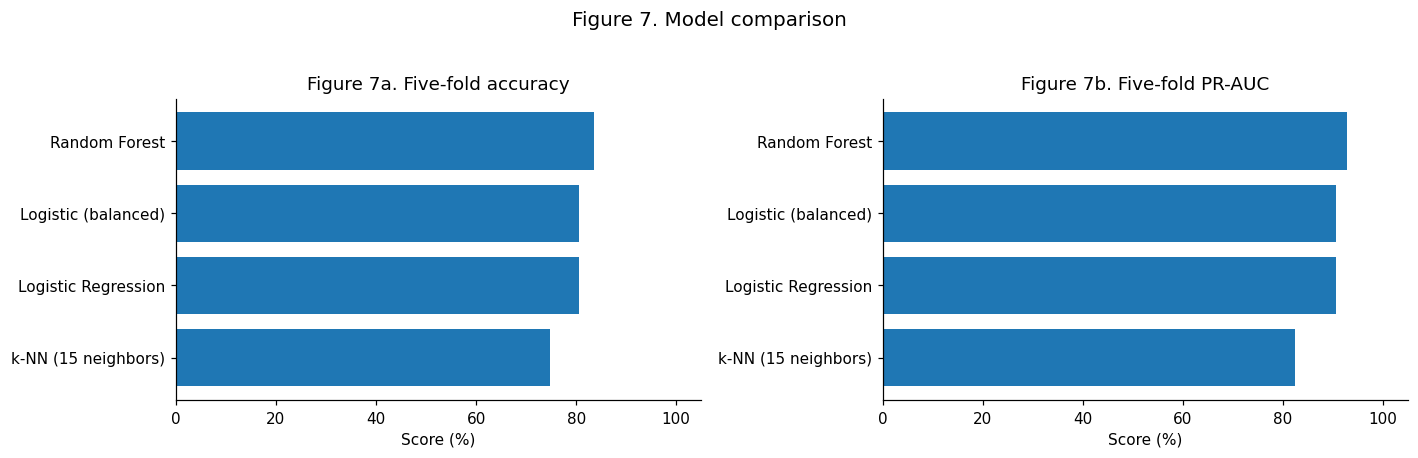

What I see: Random Forest has the highest average CV accuracy (83.6%).
I still need to test it on my held-out 20% before claiming how reliable it is.


In [18]:
fig, axs = plt.subplots(1,2,figsize=(13,4))
for ax, metric, title in zip(axs,['Accuracy','PR-AUC (AP)'], ['Figure 7a. Five-fold accuracy','Figure 7b. Five-fold PR-AUC']):
    vals = cv_table[metric].sort_values()
    ax.barh(vals.index, vals.values*100)
    ax.set(xlabel='Score (%)',title=title,xlim=(0,105))
fig.suptitle("Figure 7. Model comparison", fontsize=13, y=1.03)
plt.tight_layout(); plt.show()
print(f"What I see: {cv_table.index[0]} has the highest average CV accuracy ({cv_table.iloc[0]['Accuracy']:.1%}).")
print('I still need to test it on my held-out 20% before claiming how reliable it is.')

### 4.3 Does balancing the groups help?
A **balanced** Logistic Regression gives extra weight to the less common outcome during training. I compare it with normal Logistic Regression using the same folds.

**What I want to know:** Does balancing help me catch more cancellations (**recall**), and if it does, how much accuracy or precision do I give up?

In [19]:
balance_comparison = cv_table.loc[['Logistic Regression','Logistic (balanced)'], ['Accuracy','Precision','Recall','F1','PR-AUC (AP)']]
display((balance_comparison*100).round(2))
a = balance_comparison.loc['Logistic Regression']
b = balance_comparison.loc['Logistic (balanced)']
print(f"What I see: balancing changed recall by {(b['Recall']-a['Recall'])*100:+.1f} percentage points and accuracy by {(b['Accuracy']-a['Accuracy'])*100:+.1f} points.")
print('That lets me decide whether class weighting is worth the tradeoff.')

,Accuracy,Precision,Recall,F1,PR-AUC (AP)
Model,,,,,
Logistic Regression,80.58,81.36,80.63,80.99,90.59
Logistic (balanced),80.66,81.97,79.89,80.91,90.59


What I see: balancing changed recall by -0.7 percentage points and accuracy by +0.1 points.
That lets me decide whether class weighting is worth the tradeoff.


### 4.4 Figure 8 — Choose a prediction cutoff
A **threshold** is the number at which I decide “this person is likely to cancel.” For example, with a cutoff of **0.50**, a predicted risk of **0.60** becomes a cancellation prediction.

I try different cutoffs and compare accuracy, precision, recall and F1. **Lowering the cutoff** usually catches more possible cancellations but also creates more false alarms. I show the cutoff with the best validation accuracy and the one with the best F1.

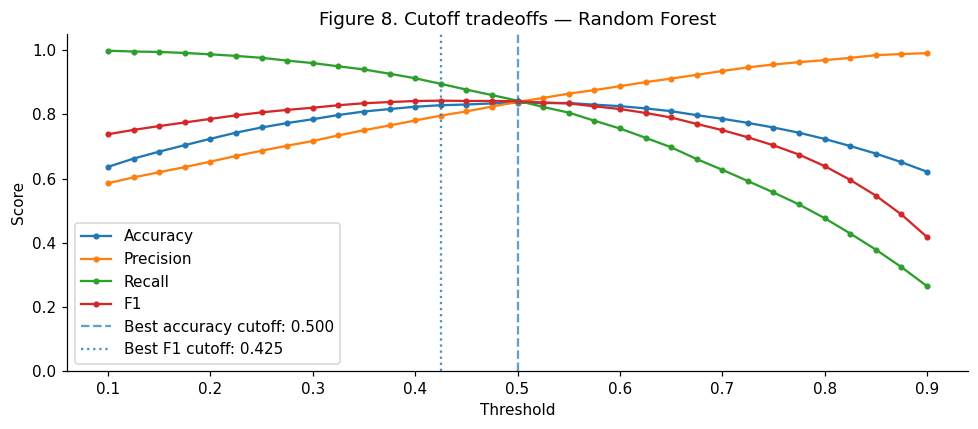

What I see: a 0.500 cutoff had the best cross-validated accuracy among the cutoffs I tried.
A 0.425 cutoff had the best F1. For outreach, I would also consider budget and cost of unnecessary discounts.


In [20]:
chosen_name = cv_table.index[0]
oof = oof_probs[chosen_name]
thresholds = np.round(np.arange(.10,.91,.025), 3)
thr_rows = [{'Threshold':t,**get_scores(y_cv,oof,t)} for t in thresholds]
threshold_table = pd.DataFrame(thr_rows)
accuracy_threshold = float(threshold_table.sort_values(['Accuracy','F1'],ascending=False).iloc[0]['Threshold'])
outreach_threshold = float(threshold_table.sort_values(['F1','Precision'],ascending=False).iloc[0]['Threshold'])
fig, ax = plt.subplots(figsize=(9,4))
for key in ['Accuracy','Precision','Recall','F1']:
    ax.plot(threshold_table.Threshold, threshold_table[key], marker='.',label=key)
ax.axvline(accuracy_threshold,ls='--',alpha=.7,label=f'Best accuracy cutoff: {accuracy_threshold:.3f}')
ax.axvline(outreach_threshold,ls=':',alpha=.8,label=f'Best F1 cutoff: {outreach_threshold:.3f}')
ax.set(title=f'Figure 8. Cutoff tradeoffs — {chosen_name}',xlabel='Threshold',ylabel='Score',ylim=(0,1.05))
ax.legend(loc='best'); plt.tight_layout(); plt.show()
print(f"What I see: a {accuracy_threshold:.3f} cutoff had the best cross-validated accuracy among the cutoffs I tried.")
print(f"A {outreach_threshold:.3f} cutoff had the best F1. For outreach, I would also consider budget and cost of unnecessary discounts.")

### 4.5 Final check on the held-out customers
Now I train the selected model with the development data and test it on the **20% that I kept separate**. That gives me a more realistic check than judging the same data used to choose the model.

I also compare accuracy with a very simple baseline: always guessing whichever class was most common.

In [21]:
chosen_pipeline = clone(model_pipelines[chosen_name])
chosen_pipeline.fit(X_dev,y_dev)
holdout_prob = chosen_pipeline.predict_proba(X_holdout)[:,1]
holdout_metrics = get_scores(y_holdout, holdout_prob, accuracy_threshold)
holdout_metrics_table = pd.Series(holdout_metrics,name='Holdout score').to_frame()
display((holdout_metrics_table*100).round(2))
print(f"What I see: My model predicted {holdout_metrics['Accuracy']:.1%} of holdout labels correctly.")
print(f"Its precision was {holdout_metrics['Precision']:.1%}, recall {holdout_metrics['Recall']:.1%}, and F1 {holdout_metrics['F1']:.1%}.")
majority_baseline = max(y_holdout.mean(), 1-y_holdout.mean())
print(f'Majority-class baseline accuracy: {majority_baseline:.1%}. My model differs by {(holdout_metrics["Accuracy"]-majority_baseline)*100:+.2f} percentage points.')
print('These results estimate performance on similar future data, but they are not a guaranteed real-world success rate.')

,Holdout score
Accuracy,84.76
Balanced accuracy,84.73
Precision,84.61
Recall,85.94
F1,85.27
ROC-AUC,93.56
PR-AUC (AP),94.05


What I see: My model predicted 84.8% of holdout labels correctly.
Its precision was 84.6%, recall 85.9%, and F1 85.3%.
Majority-class baseline accuracy: 51.3%. My model differs by +33.42 percentage points.
These results estimate performance on similar future data, but they are not a guaranteed real-world success rate.


### 4.6 Figure 9 — Confusion matrix: where did I make mistakes?
This four-square chart counts correct and incorrect predictions. The rows show **what actually happened**; the columns show **what I predicted**.

- **Top left:** Correctly predicted a customer would stay.
- **Top right:** Predicted cancellation, but the customer stayed (**false alarm**).
- **Bottom left:** Predicted staying, but the customer canceled (**missed cancellation**).
- **Bottom right:** Correctly predicted cancellation.

The main thing I want to understand is how often I miss a customer who cancels versus incorrectly flagging someone who stays.

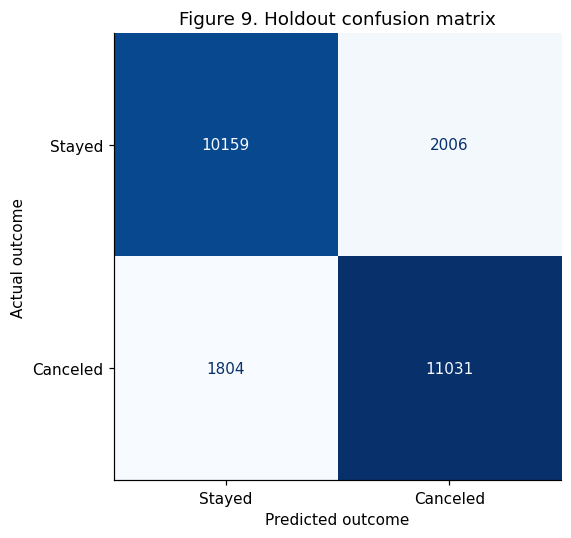

What I see: 11,031 cancellations caught, 1,804 missed, 2,006 false alarms, and 10,159 correct stay predictions.
I would pay special attention to missed cancellations and the cost of unnecessary discount offers.


In [22]:
holdout_pred = (holdout_prob >= accuracy_threshold).astype(int)
cm = confusion_matrix(y_holdout,holdout_pred,labels=[0,1])
fig,ax=plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Stayed','Canceled']).plot(ax=ax,cmap='Blues',colorbar=False,values_format='d')
ax.set(title='Figure 9. Holdout confusion matrix', xlabel='Predicted outcome', ylabel='Actual outcome')
plt.tight_layout(); plt.show()
tn,fp,fn,tp=cm.ravel()
print(f'What I see: {tp:,} cancellations caught, {fn:,} missed, {fp:,} false alarms, and {tn:,} correct stay predictions.')
print('I would pay special attention to missed cancellations and the cost of unnecessary discount offers.')

### 4.7 Figure 10 — ROC and precision–recall curves
**ROC curve (left):** I want the model line to stay above the diagonal dashed line. It means the model separates cancelers from non-cancelers better than random guessing.

**Precision–recall curve (right):** This shows the tradeoff between catching more real cancellations (**recall**) and having fewer false alarms (**precision**). I compare it with the dashed baseline, which is just the overall churn rate.

These curves look at different cutoffs, not just the one I picked.

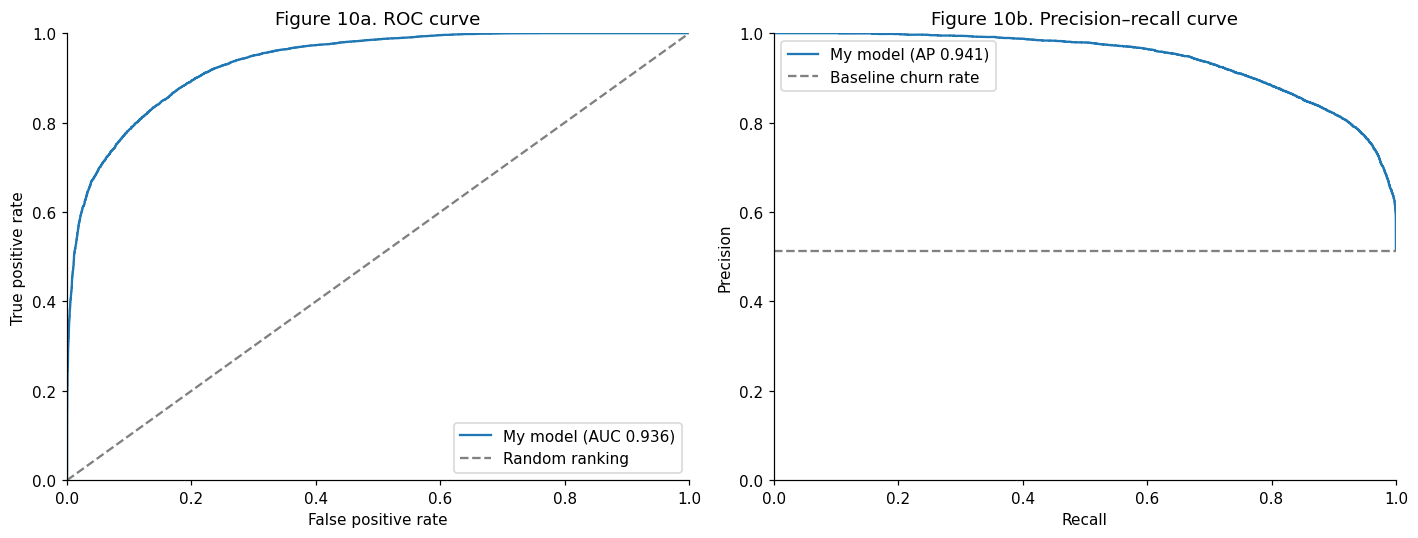

What I see: ROC-AUC = 0.936 and PR-AUC = 0.941.
The no-skill PR baseline is the holdout cancellation rate: 51.3%.
If my PR curve stays above that baseline, it is doing better than random alerts across those recall values.


In [23]:
fpr,tpr,_ = roc_curve(y_holdout,holdout_prob)
pr,rec,_ = precision_recall_curve(y_holdout,holdout_prob)
fig,axs=plt.subplots(1,2,figsize=(13,5))
axs[0].plot(fpr,tpr,label=f"My model (AUC {holdout_metrics['ROC-AUC']:.3f})")
axs[0].plot([0,1],[0,1],ls='--',color='gray',label='Random ranking')
axs[0].set(title='Figure 10a. ROC curve',xlabel='False positive rate',ylabel='True positive rate',xlim=(0,1),ylim=(0,1))
axs[0].legend()
axs[1].plot(rec,pr,label=f"My model (AP {holdout_metrics['PR-AUC (AP)']:.3f})")
axs[1].axhline(y_holdout.mean(),ls='--',color='gray',label='Baseline churn rate')
axs[1].set(title='Figure 10b. Precision–recall curve',xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1))
axs[1].legend()
plt.tight_layout(); plt.show()
print(f"What I see: ROC-AUC = {holdout_metrics['ROC-AUC']:.3f} and PR-AUC = {holdout_metrics['PR-AUC (AP)']:.3f}.")
print(f"The no-skill PR baseline is the holdout cancellation rate: {y_holdout.mean():.1%}.")
print('If my PR curve stays above that baseline, it is doing better than random alerts across those recall values.')

### 4.8 Figure 11 — Which features mattered to my model?
I look at which customer details the selected model relied on most. Larger bars mean the feature mattered more to its predictions by this method.

**Important:** A model feature being important does **not** mean changing it would cause churn to go down. It tells me where the model found useful patterns.

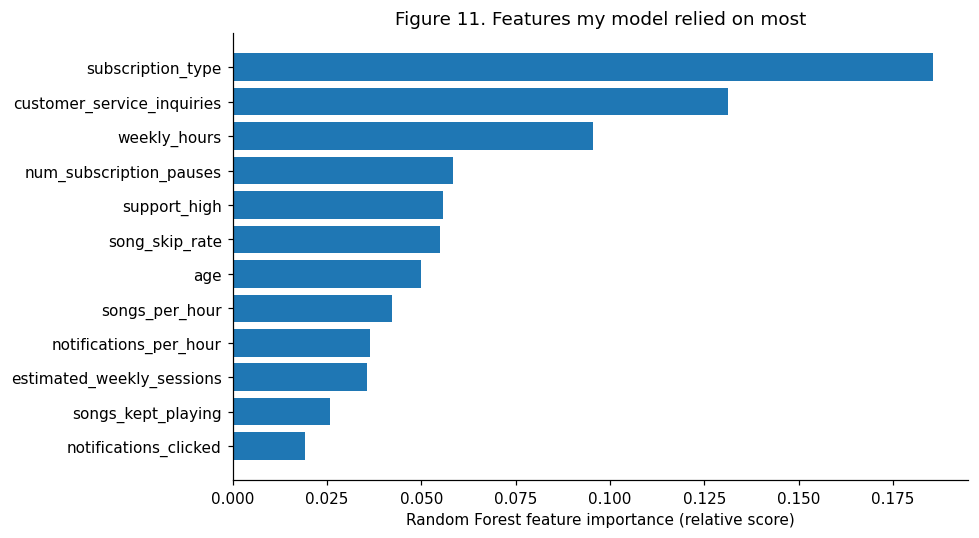

What I see: subscription_type was the highest-ranked feature by this method.
This is about the model, not proof that changing that feature will stop cancellations.


In [24]:
# This fast explanation works for the Random Forest winner and has a fallback for other models.
from sklearn.inspection import permutation_importance
fitted_estimator = chosen_pipeline.named_steps['model']
if hasattr(fitted_estimator, 'feature_importances_') or hasattr(fitted_estimator, 'coef_'):
    if hasattr(fitted_estimator, 'feature_importances_'):
        raw_importance = np.asarray(fitted_estimator.feature_importances_)
        label = 'Random Forest feature importance (relative score)'
    else:
        raw_importance = np.abs(fitted_estimator.coef_).mean(axis=0)
        label = 'Absolute model coefficient (rough importance)'
    scores = dict(zip(numeric_cols, raw_importance[:len(numeric_cols)]))
    encoder_fit = chosen_pipeline.named_steps['prep'].named_transformers_['category'].named_steps['encode']
    offset = len(numeric_cols)
    for col, categories in zip(category_cols, encoder_fit.categories_):
        width = len(categories)
        scores[col] = float(raw_importance[offset:offset + width].sum())
        offset += width
    assert offset == len(raw_importance), 'One-hot importance mapping did not match.'
    importance = pd.Series(scores).sort_values(ascending=False)
else:
    # KNN has no built-in weights; use a small holdout sample to keep it practical.
    X_example = X_holdout.sample(n=min(60,len(X_holdout)),random_state=SEED)
    y_example = y_holdout.loc[X_example.index]
    result = permutation_importance(chosen_pipeline, X_example, y_example,
                                    n_repeats=1,random_state=SEED,
                                    scoring='average_precision',n_jobs=1)
    importance = pd.Series(result.importances_mean,index=X.columns).sort_values(ascending=False)
    label = 'Change in average precision after shuffling a feature'
important = importance.head(12).sort_values()
fig,ax=plt.subplots(figsize=(9,5))
ax.barh(important.index, important.values)
ax.set(title='Figure 11. Features my model relied on most',xlabel=label)
plt.tight_layout();plt.show()
print(f'What I see: {importance.index[0]} was the highest-ranked feature by this method.')
print('This is about the model, not proof that changing that feature will stop cancellations.')

## Task 5 — Final predictions, what I learned and retention ideas
